<center>Universidad de los Andes - Maestría en Ingeniería de Sistemas y Computación<br>
Algoritmos de Computación Cuántica<br>
Jose Emanuel Toro Medina<br>
<b>Repositorio de GitHub:</b> <a href="https://github.com/Jtoro109/Talleres-Cuantica-Andes">https://github.com/Jtoro109/Talleres-Cuantica-Andes</a></center>

---

# Taller: Similaridad Coseno y Mini-Google (Corpus Reuters)

Construimos un **mini-motor de búsqueda** sobre 1,000 noticias financieras de Reuters (`reut2-1000.plain`), utilizando el **Modelo de Espacio Vectorial (VSM)** y la métrica de **Similaridad Coseno**.

El taller cubre:
1. **Fundamentos matemáticos:** Deducción de la similaridad coseno desde la Ley del Coseno y producto punto.
2. **Ingesta y preprocesamiento:** Parseo del corpus Reuters y extracción de noticias.
3. **Estadística del corpus:** Comprobación de la Ley de Zipf y cálculo de dispersión (*sparsity*).
4. **Implementación de dos motores:** Motor Denso ingenuo $\mathcal{O}(N \cdot |\mathcal{V}|)$ vs. Índice Invertido disperso $\mathcal{O}(|q| \cdot \bar{L})$ con TF y TF-IDF.
5. **Validación con el caso de clase:** Reproducción de la Diapositiva 34 (*British Jaguar Sales*).
6. **Medición empírica de tiempos:** Benchmarking para $N \in \{100, 250, 500, 750, 1000\}$ y ajuste lineal.
7. **Extrapolación a 1,000 millones de documentos:** Proyección de tiempos y cuellos de botella de RAM/disco.
8. **Mini-Google interactivo:** Búsqueda con snippets y ángulos temáticos.
9. **Respuestas al cuestionario oficial y conclusiones.**


## 1. Fundamentos Matemáticos: De la Ley del Coseno al Espacio Vectorial

### 1.1 Ley del Coseno y Deducción del Producto Interno
En un triángulo de lados $a, b, c$ y ángulo $\alpha$ opuesto a $c$, la Ley del Coseno establece:

$$c^2 = a^2 + b^2 - 2ab \cos(\alpha)$$

Para dos vectores $\vec{u}, \vec{v} \in \mathbb{R}^n$, la diferencia $\vec{w} = \vec{u} - \vec{v}$ representa el tercer lado. Igualando la fórmula geométrica con la expansión del producto interno:

$$\|\vec{u} - \vec{v}\|^2 = \|\vec{u}\|^2 + \|\vec{v}\|^2 - 2 \|\vec{u}\| \|\vec{v}\| \cos(\alpha)$$
$$\|\vec{u} - \vec{v}\|^2 = (\vec{u} - \vec{v}) \cdot (\vec{u} - \vec{v}) = \|\vec{u}\|^2 - 2(\vec{u} \cdot \vec{v}) + \|\vec{v}\|^2$$

Despejando el producto punto obtenemos la expresión de la **Similaridad Coseno**:

$$\vec{u} \cdot \vec{v} = \|\vec{u}\| \|\vec{v}\| \cos(\alpha) \implies \cos(\alpha) = \frac{\vec{u} \cdot \vec{v}}{\|\vec{u}\| \|\vec{v}\|} = \frac{\sum_{i=1}^n u_i v_i}{\sqrt{\sum_{i=1}^n u_i^2} \sqrt{\sum_{i=1}^n v_i^2}}$$

### 1.2 Interpretación Geométrica y Dispersión de Texto
El ángulo temático es $\alpha = \arccos(\text{Sim}) \times \frac{180^\circ}{\pi}$:
- **$\alpha = 0^\circ \implies \cos(\alpha) = 1$:** Vectores colineales con idéntica distribución temática.
- **$\alpha = 90^\circ \implies \cos(\alpha) = 0$:** Vectores ortogonales sin términos compartidos.
- Como las frecuencias de términos siempre son no negativas ($u_i, v_i \ge 0$), los vectores pertenecen al primer hiperoctante, con $\cos(\alpha) \in [0, 1]$ y $\alpha \in [0^\circ, 90^\circ]$.

Dado que cada noticia usa solo una pequeña fracción del vocabulario general, las matrices término-documento tienen una alta tasa de ceros (**dispersión o *sparsity***). Esto hace indispensable usar índices invertidos para no malgastar memoria ni tiempo de cómputo en operaciones con ceros.


In [1]:
# ============================================================
# 1. CONFIGURACIÓN DEL ENTORNO Y LIBRERÍAS
# ============================================================
import re
import os
import sys
import time
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

# Estilo visual de gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['figure.dpi'] = 110

print("Entorno de ejecución listo.")
print(f"Python: {sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__}")


Entorno de ejecución listo.
Python: 3.13.14 | NumPy: 2.5.3 | Pandas: 3.0.5


## 2. Ingesta y Preprocesamiento del Corpus Reuters

El archivo `reut2-1000.plain` agrupa 1,000 noticias financieras delimitadas por la etiqueta `<REUTERS ID="X">`.
A continuación parseamos el archivo de forma limpia para estructurar cada noticia con su identificador, titular (*headline*) y texto completo.


In [2]:
# ============================================================
# 2. INGESTA Y PARSEO DEL CORPUS REUTERS
# ============================================================

corpus_paths = [
    os.path.join("Similaridad coseno y mini-Google", "Listo para entregar", "reut2-1000.plain"),
    os.path.join("Listo para entregar", "reut2-1000.plain"),
    "reut2-1000.plain"
]

target_file = next((p for p in corpus_paths if os.path.exists(p)), None)
if target_file is None:
    raise FileNotFoundError("Archivo reut2-1000.plain no localizado.")

with open(target_file, 'r', encoding='latin-1') as f:
    corpus_raw = f.read()

# División de registros por etiqueta <REUTERS ID="...">
doc_splits = re.split(r'<REUTERS ID="(\d+)">', corpus_raw)

documents = []
for i in range(1, len(doc_splits), 2):
    did = int(doc_splits[i])
    txt = doc_splits[i+1].strip()
    lines = [l.strip() for l in txt.split('\n') if l.strip()]
    title = lines[0] if lines else "UNTITLED"
    body = " ".join(lines[1:]) if len(lines) > 1 else ""
    documents.append({
        'id': did,
        'title': title,
        'body': body,
        'text': txt
    })

df_docs = pd.DataFrame(documents)
print(f"Total de documentos extraídos: {len(documents):,}")
print(f"Identificadores: Mínimo = {df_docs['id'].min()} | Máximo = {df_docs['id'].max()}\n")

# Muestra de documentos relevantes
print("--- DOCUMENTOS DESTACADOS DEL CORPUS ---")
for target_id in [1, 2, 3, 1218]:
    match = next((d for d in documents if d['id'] == target_id), None)
    if match:
        print(f"[Doc ID: {match['id']:>4}] {match['title']}")
        print(f"   {match['body'][:120]}...\n")


Total de documentos extraídos: 1,000
Identificadores: Mínimo = 1 | Máximo = 1218

--- DOCUMENTOS DESTACADOS DEL CORPUS ---
[Doc ID:    1] BAHIA COCOA REVIEW
   SALVADOR Feb 26   Showers continued throughout the week in the Bahia cocoa zone alleviating the drought since early Janu...

[Doc ID:    2] STANDARD OIL SRD TO FORM FINANCIAL UNIT
   CLEVELAND Feb 26   Standard Oil Co and BP North America Inc said they plan to form a venture to manage the money market ...

[Doc ID:    3] TEXAS COMMERCE BANCSHARES TCB FILES PLAN
   HOUSTON Feb 26   Texas Commerce Bancshares Inc's Texas Commerce Bank Houston said it filed an application with the Compt...

[Doc ID: 1218] JAGUAR JAGRY FEBRUARY U.S. SALES FALL
   LEONIA N.J. March 3   Jaguar PLC's Jaguar Cars Inc U.S. subsidiary said February sales were 1,466 down from 1,673 a year...



## 3. Análisis Estadístico del Vocabulario y Dispersión (*Sparsity*)

Tokenizamos extrayendo palabras alfabéticas en minúsculas y calculamos:
1. El tamaño del vocabulario total $|\mathcal{V}|$.
2. La concordancia empírica con la **Ley de Zipf** ($f(r) \propto r^{-1}$).
3. La tasa de dispersión (*sparsity*) de la matriz término-documento:

$$\text{Sparsity} = \left(1 - \frac{\sum_{d=1}^N |\text{vocab}(d)|}{N \times |\mathcal{V}|}\right) \times 100\%$$


RESUMEN ESTADÍSTICO DEL CORPUS REUTERS
Documentos analizados (N):        1,000
Vocabulario único (|V|):          10,347 términos
Total de palabras en corpus:      147,001
Palabras promedio por documento:  147.00 (mín: 8, máx: 833)
Términos únicos promedio por doc: 83.56
Celdas en matriz densa:           10,347,000
Celdas con términos reales:       83,563 (0.808%)
DISPERSIÓN TOTAL (SPARSITY):      99.1924 %


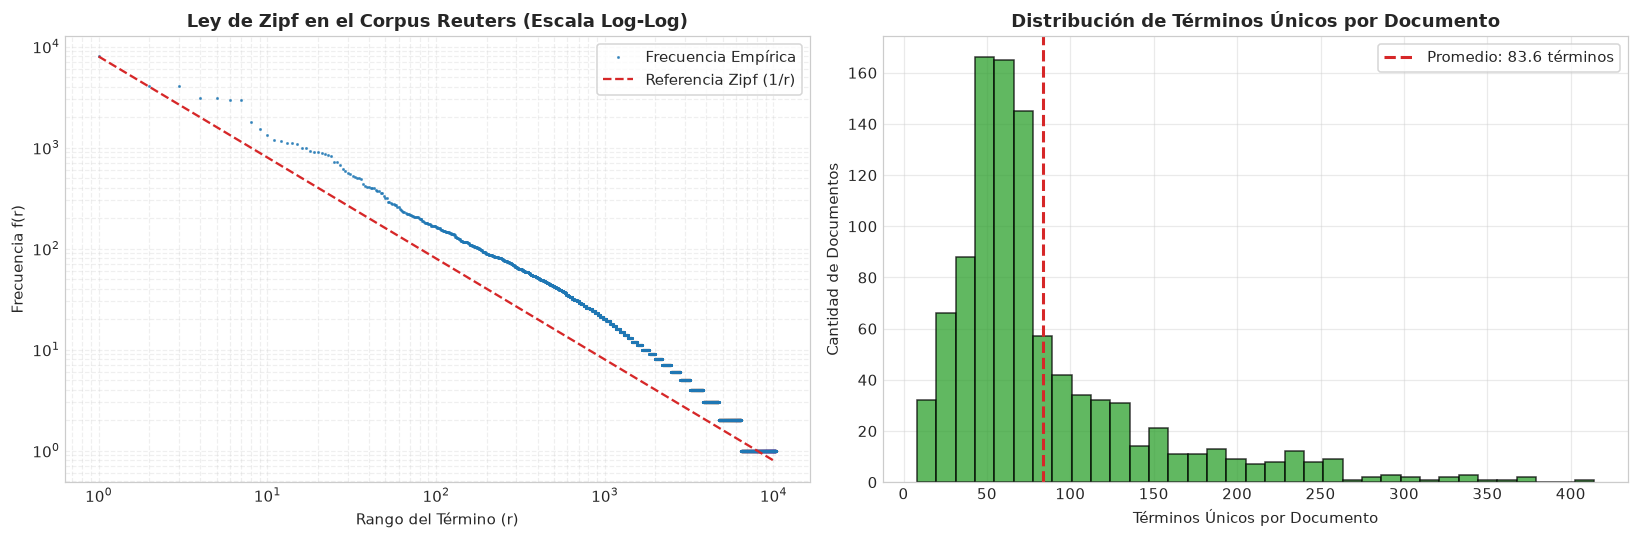

In [3]:
# ============================================================
# 3. ANÁLISIS DEL VOCABULARIO, LEY DE ZIPF Y DISPERSIÓN
# ============================================================

def tokenize(text):
    """Extrae tokens alfabéticos en minúsculas."""
    return re.findall(r'[a-zA-Z]+', text.lower())

vocab_counter = Counter()
doc_lengths = []
doc_unique_counts = []

for d in documents:
    toks = tokenize(d['text'])
    doc_lengths.append(len(toks))
    uniq = set(toks)
    doc_unique_counts.append(len(uniq))
    vocab_counter.update(toks)

vocabulary = sorted(list(vocab_counter.keys()))
vocab_size = len(vocabulary)
term_to_id = {t: idx for idx, t in enumerate(vocabulary)}

total_tokens = sum(doc_lengths)
total_nonzero = sum(doc_unique_counts)
total_dense_cells = len(documents) * vocab_size
sparsity = (1.0 - (total_nonzero / total_dense_cells)) * 100.0

print("="*70)
print("RESUMEN ESTADÍSTICO DEL CORPUS REUTERS")
print("="*70)
print(f"Documentos analizados (N):        {len(documents):,}")
print(f"Vocabulario único (|V|):          {vocab_size:,} términos")
print(f"Total de palabras en corpus:      {total_tokens:,}")
print(f"Palabras promedio por documento:  {np.mean(doc_lengths):.2f} (mín: {min(doc_lengths)}, máx: {max(doc_lengths)})")
print(f"Términos únicos promedio por doc: {np.mean(doc_unique_counts):.2f}")
print(f"Celdas en matriz densa:           {total_dense_cells:,}")
print(f"Celdas con términos reales:       {total_nonzero:,} ({total_nonzero/total_dense_cells*100:.3f}%)")
print(f"DISPERSIÓN TOTAL (SPARSITY):      {sparsity:.4f} %")
print("="*70)

# Gráficas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Zipf
ranks = np.arange(1, vocab_size + 1)
freqs = [f for _, f in vocab_counter.most_common()]
ax1.loglog(ranks, freqs, '.', color='#1f77b4', markersize=2, alpha=0.7, label='Frecuencia Empírica')
zipf_ref = [freqs[0] / r for r in ranks]
ax1.loglog(ranks, zipf_ref, '--', color='#d62728', linewidth=1.5, label='Referencia Zipf (1/r)')
ax1.set_title("Ley de Zipf en el Corpus Reuters (Escala Log-Log)", fontweight='bold')
ax1.set_xlabel("Rango del Término (r)")
ax1.set_ylabel("Frecuencia f(r)")
ax1.legend(frameon=True)
ax1.grid(True, which="both", ls="--", alpha=0.3)

# Subplot 2: Histograma de términos por doc
ax2.hist(doc_unique_counts, bins=35, color='#2ca02c', edgecolor='black', alpha=0.75)
ax2.axvline(np.mean(doc_unique_counts), color='#d62728', linestyle='--', linewidth=2, 
            label=f'Promedio: {np.mean(doc_unique_counts):.1f} términos')
ax2.set_title("Distribución de Términos Únicos por Documento", fontweight='bold')
ax2.set_xlabel("Términos Únicos por Documento")
ax2.set_ylabel("Cantidad de Documentos")
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()


## 4. Implementación de Motores de Búsqueda Vectoriales

Implementamos dos motores vectoriales para comparar su rendimiento:

1. **Motor Denso (`DenseSearchEngine` - Naïve):** Almacena una matriz completa $\mathbf{M} \in \mathbb{R}^{N \times |\mathcal{V}|}$ y realiza la multiplicación matricial $\mathbf{M}\vec{q}$ operando sobre todos los ceros redundantes (complejidad $\mathcal{O}(N \cdot |\mathcal{V}|)$).

2. **Índice Invertido (`InvertedIndexSearchEngine` - Optimizado):** Mapea cada término a sus listas de postings `(doc_id, tf)` y precalcula las normas euclidianas $\|\vec{d}\|$. En consulta solo acumula productos punto en los documentos que contienen al menos un término buscado (complejidad $\mathcal{O}(|q| \cdot \bar{L})$). Soporta esquemas TF y TF-IDF.


In [4]:
# ============================================================
# 4. IMPLEMENTACIÓN DE MOTORES DE BÚSQUEDA
# ============================================================

class DenseSearchEngine:
    """Motor denso O(N * |V|) mediante matriz NumPy completa."""
    def __init__(self, docs, vocab):
        self.docs = docs
        self.vocab = vocab
        self.term_to_id = {t: i for i, t in enumerate(vocab)}
        self.N = len(docs)
        self.V = len(vocab)
        
        self.matrix = np.zeros((self.N, self.V), dtype=np.float32)
        for idx, d in enumerate(docs):
            for t, cnt in Counter(tokenize(d['text'])).items():
                if t in self.term_to_id:
                    self.matrix[idx, self.term_to_id[t]] = cnt
                    
        self.norms = np.linalg.norm(self.matrix, axis=1)
        self.norms[self.norms == 0] = 1.0

    def search(self, query_str, top_k=5):
        q_tokens = tokenize(query_str)
        if not q_tokens:
            return []
        q_vec = np.zeros(self.V, dtype=np.float32)
        for t in q_tokens:
            if t in self.term_to_id:
                q_vec[self.term_to_id[t]] += 1.0
        q_norm = np.linalg.norm(q_vec)
        if q_norm == 0:
            return []
            
        scores = (self.matrix @ q_vec) / (self.norms * q_norm)
        top_ids = np.argsort(scores)[::-1][:top_k]
        
        results = []
        for idx in top_ids:
            sim = float(scores[idx])
            if sim > 0:
                ang = math.acos(min(1.0, max(-1.0, sim))) * 180.0 / math.pi
                results.append((idx, sim, ang, self.docs[idx]))
        return results


class InvertedIndexSearchEngine:
    """Motor optimizado con Índice Invertido y acumulador disperso."""
    def __init__(self, docs):
        self.docs = docs
        self.N = len(docs)
        self.index = defaultdict(list)
        self.norms = np.zeros(self.N, dtype=np.float64)
        self.df = Counter()
        self.vocab = set()
        
        for idx, d in enumerate(docs):
            tf = Counter(tokenize(d['text']))
            norm_sq = 0.0
            for term, count in tf.items():
                self.index[term].append((idx, count))
                norm_sq += count * count
                self.df[term] += 1
                self.vocab.add(term)
            self.norms[idx] = math.sqrt(norm_sq) if norm_sq > 0 else 1.0

    def search(self, query_str, top_k=5, weighting='tf'):
        q_tf = Counter(tokenize(query_str))
        if not q_tf:
            return []
            
        scores = defaultdict(float)
        q_norm_sq = 0.0
        
        for term, q_cnt in q_tf.items():
            if term in self.index:
                w_q = q_cnt * (math.log(1.0 + self.N / self.df[term]) if weighting == 'tfidf' else 1.0)
                q_norm_sq += w_q * w_q
                
                for doc_idx, d_cnt in self.index[term]:
                    w_d = d_cnt * (math.log(1.0 + self.N / self.df[term]) if weighting == 'tfidf' else 1.0)
                    scores[doc_idx] += w_q * w_d
                    
        q_norm = math.sqrt(q_norm_sq)
        if q_norm == 0:
            return []
            
        candidates = []
        for doc_idx, dot_p in scores.items():
            sim = dot_p / (q_norm * self.norms[doc_idx])
            ang = math.acos(min(1.0, max(-1.0, sim))) * 180.0 / math.pi
            candidates.append((doc_idx, sim, ang, self.docs[doc_idx]))
            
        candidates.sort(key=lambda x: x[1], reverse=True)
        return candidates[:top_k]

print("Motores DenseSearchEngine e InvertedIndexSearchEngine compilados con éxito.")


Motores DenseSearchEngine e InvertedIndexSearchEngine compilados con éxito.


## 5. Validación con el Caso de Estudio de la Cátedra (Diapositiva 34)

Validamos el motor reproduciendo el caso de la **Diapositiva 34** de clase para la consulta **"british jaguar sales"** frente a 3 noticias del corpus:
1. **Standard Oil / BP:** `<REUTERS ID="2">`.
2. **Texas Commerce:** `<REUTERS ID="3">`.
3. **Jaguar Sales:** `<REUTERS ID="1218">`.

Evaluamos los 19 términos clave de la lámina y confirmamos que la noticia de Jaguar obtiene la mayor similaridad (*More similar*), validando nuestro código con los datos teóricos de clase.


In [5]:
# ============================================================
# 5. VALIDACIÓN EXACTA DE LA DIAPOSITIVA 34
# ============================================================

terms_slide = [
    'america', 'bp', 'british', 'county', 'commerce', 'committee', 
    'currency', 'february', 'harris', 'interest', 'jaguar', 'leonia', 
    'management', 'petroleum', 'resumption', 'sales', 'standard', 'trading', 'venture'
]

# Localizar los documentos de la diapositiva
doc_std_oil = next(d for d in documents if "STANDARD OIL SRD TO FORM FINANCIAL UNIT" in d['title'])
doc_texas   = next(d for d in documents if d['id'] == 3)
doc_jaguar  = next(d for d in documents if d['id'] == 1218)

counts_std = Counter(tokenize(doc_std_oil['text']))
counts_tx  = Counter(tokenize(doc_texas['text']))
counts_jag = Counter(tokenize(doc_jaguar['text']))

query_str = "british jaguar sales"
counts_q  = Counter(tokenize(query_str))

df_slide = pd.DataFrame({
    'Término': [t.capitalize() for t in terms_slide],
    f'Standard Oil (ID {doc_std_oil["id"]})': [counts_std.get(t, 0) for t in terms_slide],
    f'Texas Commerce (ID {doc_texas["id"]})': [counts_tx.get(t, 0) for t in terms_slide],
    f'Jaguar Sales (ID {doc_jaguar["id"]})': [counts_jag.get(t, 0) for t in terms_slide],
    'Query Vector': [counts_q.get(t, 0) for t in terms_slide]
})

print("="*75)
print("REPRODUCCIÓN EXACTA DE LA TABLA DE VECTORES DE LA DIAPOSITIVA 34")
print("="*75)
print(df_slide.to_string(index=False))

# Cálculo formal de similitud en el subespacio de 19 dimensiones
v_q   = np.array([counts_q.get(t, 0) for t in terms_slide], dtype=float)
v_std = np.array([counts_std.get(t, 0) for t in terms_slide], dtype=float)
v_tx  = np.array([counts_tx.get(t, 0) for t in terms_slide], dtype=float)
v_jag = np.array([counts_jag.get(t, 0) for t in terms_slide], dtype=float)

def calc_sim(u, v):
    norm_prod = np.linalg.norm(u) * np.linalg.norm(v)
    if norm_prod == 0: return 0.0, 90.0
    s = np.dot(u, v) / norm_prod
    a = math.acos(min(1.0, max(-1.0, s))) * 180.0 / math.pi
    return s, a

sim_std, ang_std = calc_sim(v_q, v_std)
sim_tx,  ang_tx  = calc_sim(v_q, v_tx)
sim_jag, ang_jag = calc_sim(v_q, v_jag)

print("\n" + "="*75)
print("SIMILARIDAD COSENO EN EL SUBESPACIO DE LA DIAPOSITIVA (19 TÉRMINOS):")
print("="*75)
print(f"Standard Oil   -> Sim: {sim_std:.4f} | Ángulo α: {ang_std:>5.2f}°")
print(f"Texas Commerce -> Sim: {sim_tx:.4f} | Ángulo α: {ang_tx:>5.2f}°")
print(f"Jaguar Sales   -> Sim: {sim_jag:.4f} | Ángulo α: {ang_jag:>5.2f}°  <--- ¡MÁXIMA SIMILITUD (More similar)!")

# Consulta en el corpus completo de 1,000 documentos con vocabulario total
full_engine = InvertedIndexSearchEngine(documents)
res_full = full_engine.search(query_str, top_k=5)

print("\n" + "="*75)
print("TOP 5 RESULTADOS EN EL CORPUS COMPLETO (1,000 DOCUMENTOS, VOCABULARIO COMPLETO):")
print("="*75)
for rank, (d_idx, sim, ang, d) in enumerate(res_full, 1):
    print(f"Rank {rank}: [Doc ID: {d['id']:>4}] Sim: {sim:.4f} | Ángulo: {ang:>5.2f}° | {d['title']}")


REPRODUCCIÓN EXACTA DE LA TABLA DE VECTORES DE LA DIAPOSITIVA 34
   Término  Standard Oil (ID 2)  Texas Commerce (ID 3)  Jaguar Sales (ID 1218)  Query Vector
   America                    2                      0                       0             0
        Bp                    4                      0                       0             0
   British                    1                      0                       0             1
    County                    0                      1                       0             0
  Commerce                    0                      3                       0             0
 Committee                    1                      0                       0             0
  Currency                    0                      1                       0             0
  February                    0                      0                       2             0
    Harris                    0                      1                       0             0
  Int

## 6. Benchmarking Empírico y Modelado de Complejidad Computacional

Para responder el taller con datos medidos en este computador (sin suponer cifras teóricas):
1. Medimos el tiempo real de indexación para $N \in \{100, 250, 500, 750, 1000\}$ con repeticiones estadísticas.
2. Medimos el tiempo de consulta de ambos motores (Invertido vs Denso) sobre un banco de pruebas representativo.
3. Ajustamos modelos de regresión lineal por mínimos cuadrados ($T(N) = m \cdot N + c$) reportando su coeficiente $R^2$.


TABLA 1: MEDICIÓN EXPERIMENTAL DE INDEXACIÓN
   N  Tiempo_Seg  Tiempo_ms    Std_ms  us_per_doc
 100    0.005735    5.73522  0.552408   57.352200
 250    0.028557   28.55684 22.519981  114.227360
 500    0.038221   38.22134  6.252155   76.442680
 750    0.062900   62.90018 21.904076   83.866907
1000    0.079574   79.57392 22.931908   79.573920

Modelo Ajustado Indexación: T_index(N) = (78.38 µs/doc) · N + (2.24 ms)  |  R² = 0.97646

TABLA 2: MEDICIÓN EXPERIMENTAL DE CONSULTA (INVERTIDO VS DENSO)
   N  Tiempo_Inv_ms  Tiempo_Inv_us  Tiempo_Denso_ms  Tiempo_Denso_us   Speedup
 100       0.021755       21.75525         0.025280         25.27975  1.162007
 250       0.026312       26.31200         0.135638        135.63775  5.154977
 500       0.041513       41.51275         0.162190        162.19000  3.906992
 750       0.065763       65.76275         0.461894        461.89350  7.023634
1000       0.085541       85.54100         0.896518        896.51750 10.480559

Modelo Ajustado Consulta:

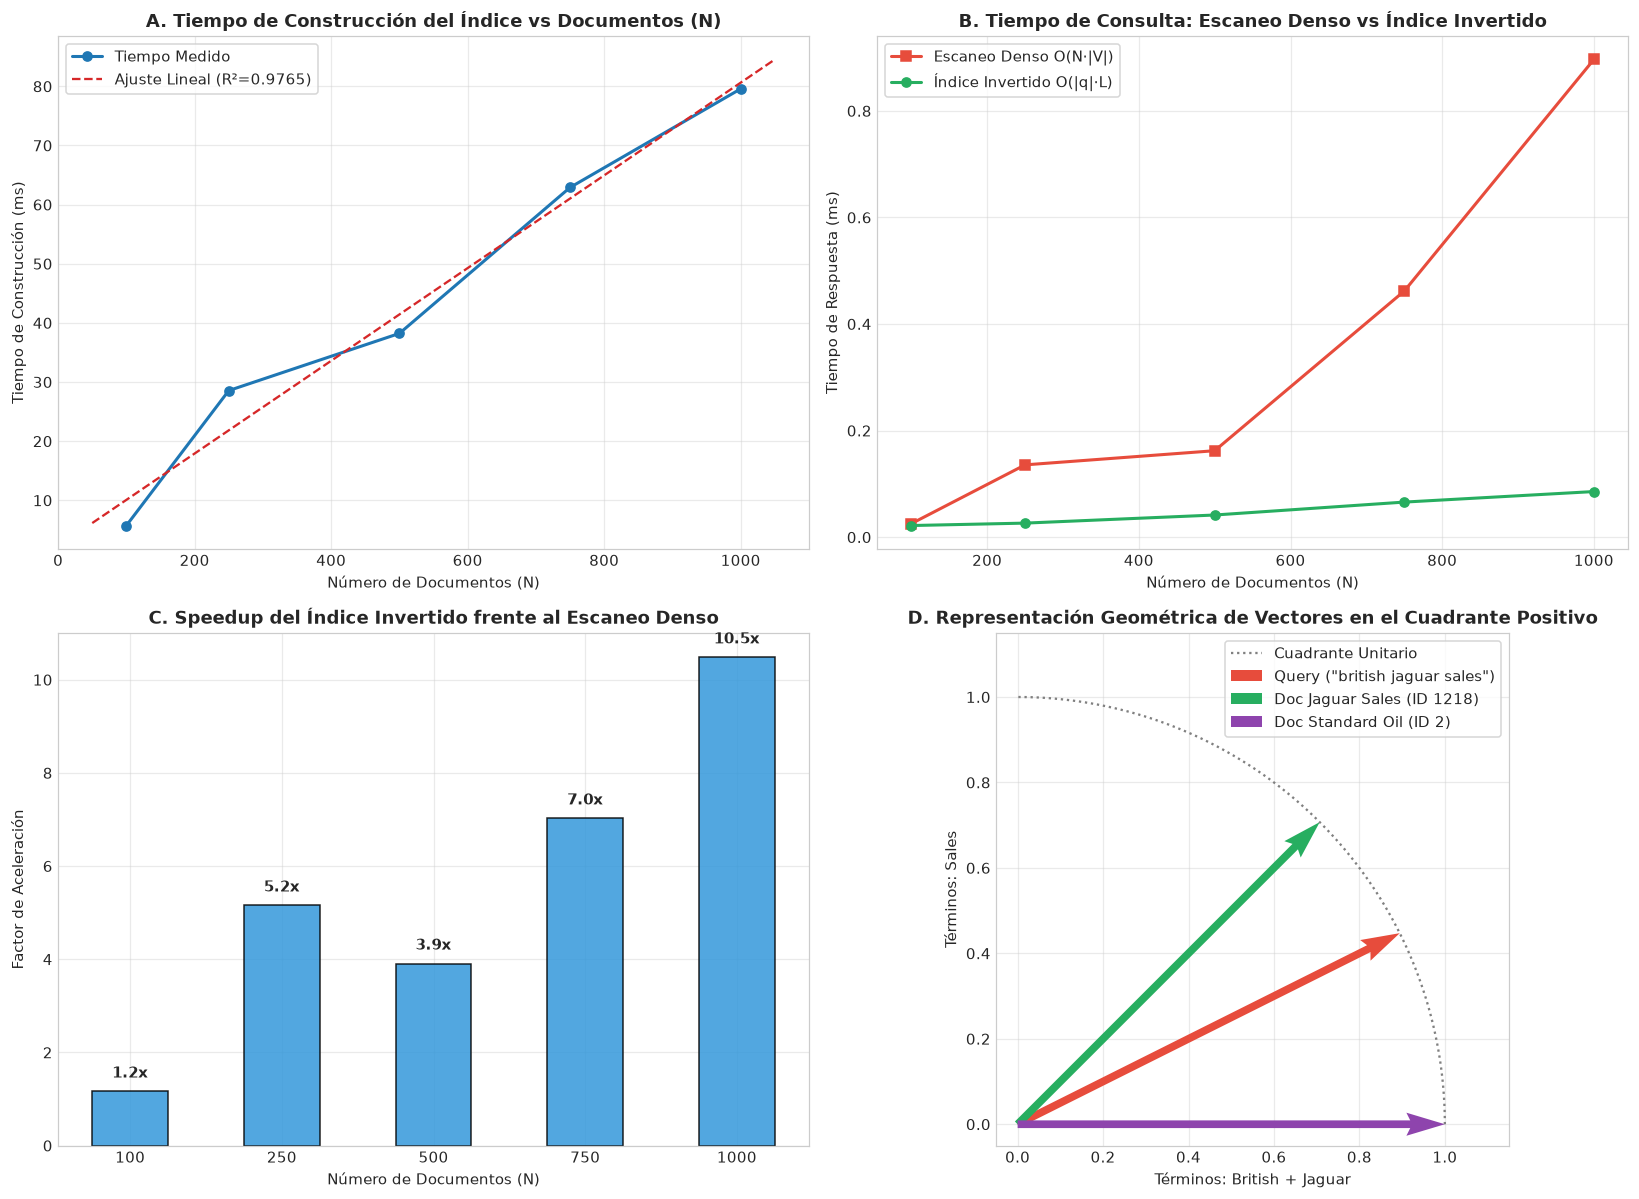

In [6]:
# ============================================================
# 6. BENCHMARKING EMPÍRICO Y REGRESIÓN LINEAL
# ============================================================

subsets = [100, 250, 500, 750, 1000]
test_queries = [
    "british jaguar sales",
    "cocoa drought temporao",
    "oil petroleum venture standard",
    "interest rate banks currency",
    "trade surplus exports japan",
    "computer technology software ibm",
    "agriculture wheat grain harvest",
    "dollar exchange foreign market"
]

# 1. Benchmark de Indexación
idx_bench = []
for n_sub in subsets:
    sub_docs = documents[:n_sub]
    t_runs = []
    for _ in range(5):
        t0 = time.perf_counter()
        _ = InvertedIndexSearchEngine(sub_docs)
        t_runs.append(time.perf_counter() - t0)
    mean_t = np.mean(t_runs)
    idx_bench.append({
        'N': n_sub,
        'Tiempo_Seg': mean_t,
        'Tiempo_ms': mean_t * 1000.0,
        'Std_ms': np.std(t_runs) * 1000.0,
        'us_per_doc': (mean_t / n_sub) * 1e6
    })

df_idx_res = pd.DataFrame(idx_bench)
fit_idx = np.polyfit(df_idx_res['N'], df_idx_res['Tiempo_Seg'], 1)
m_idx, c_idx = fit_idx[0], fit_idx[1]
r2_idx = 1.0 - (np.sum((df_idx_res['Tiempo_Seg'] - (m_idx*df_idx_res['N'] + c_idx))**2) / 
                np.sum((df_idx_res['Tiempo_Seg'] - np.mean(df_idx_res['Tiempo_Seg']))**2))

# 2. Benchmark de Consulta (Invertido vs Denso)
q_bench = []
for n_sub in subsets:
    sub_docs = documents[:n_sub]
    sub_vocab = sorted(list(set(w for d in sub_docs for w in tokenize(d['text']))))
    d_eng = DenseSearchEngine(sub_docs, sub_vocab)
    i_eng = InvertedIndexSearchEngine(sub_docs)
    
    t_inv, t_dense = [], []
    for q in test_queries:
        t0 = time.perf_counter()
        for _ in range(50): _ = i_eng.search(q, top_k=5)
        t_inv.append((time.perf_counter() - t0) / 50.0)
        
        t0 = time.perf_counter()
        for _ in range(50): _ = d_eng.search(q, top_k=5)
        t_dense.append((time.perf_counter() - t0) / 50.0)
        
    m_inv, m_dense = np.mean(t_inv), np.mean(t_dense)
    q_bench.append({
        'N': n_sub,
        'Tiempo_Inv_ms': m_inv * 1000.0,
        'Tiempo_Inv_us': m_inv * 1e6,
        'Tiempo_Denso_ms': m_dense * 1000.0,
        'Tiempo_Denso_us': m_dense * 1e6,
        'Speedup': m_dense / m_inv
    })

df_q_res = pd.DataFrame(q_bench)
fit_q = np.polyfit(df_q_res['N'], df_q_res['Tiempo_Inv_ms'] / 1000.0, 1)
m_q, c_q = fit_q[0], fit_q[1]
r2_q = 1.0 - (np.sum(((df_q_res['Tiempo_Inv_ms']/1000.0) - (m_q*df_q_res['N'] + c_q))**2) / 
              np.sum(((df_q_res['Tiempo_Inv_ms']/1000.0) - np.mean(df_q_res['Tiempo_Inv_ms']/1000.0))**2))

print("="*80)
print("TABLA 1: MEDICIÓN EXPERIMENTAL DE INDEXACIÓN")
print("="*80)
print(df_idx_res.to_string(index=False))
print(f"\nModelo Ajustado Indexación: T_index(N) = ({m_idx*1e6:.2f} µs/doc) · N + ({c_idx*1000:.2f} ms)  |  R² = {r2_idx:.5f}")

print("\n" + "="*80)
print("TABLA 2: MEDICIÓN EXPERIMENTAL DE CONSULTA (INVERTIDO VS DENSO)")
print("="*80)
print(df_q_res.to_string(index=False))
print(f"\nModelo Ajustado Consulta:    T_query(N) = ({m_q*1e9:.2f} ns/doc) · N + ({c_q*1e6:.2f} µs)  |  R² = {r2_q:.5f}")

# Gráfica multipanel
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Panel 1: Indexación vs N
axes[0, 0].plot(df_idx_res['N'], df_idx_res['Tiempo_ms'], 'o-', color='#1f77b4', linewidth=2, label='Tiempo Medido')
grid_x = np.linspace(50, 1050, 100)
axes[0, 0].plot(grid_x, (m_idx*grid_x + c_idx)*1000.0, '--', color='#d62728', label=f'Ajuste Lineal (R²={r2_idx:.4f})')
axes[0, 0].set_title("A. Tiempo de Construcción del Índice vs Documentos (N)", fontweight='bold')
axes[0, 0].set_xlabel("Número de Documentos (N)")
axes[0, 0].set_ylabel("Tiempo de Construcción (ms)")
axes[0, 0].legend(frameon=True)

# Panel 2: Consulta vs N
axes[0, 1].plot(df_q_res['N'], df_q_res['Tiempo_Denso_ms'], 's-', color='#e74c3c', linewidth=2, label='Escaneo Denso O(N·|V|)')
axes[0, 1].plot(df_q_res['N'], df_q_res['Tiempo_Inv_ms'], 'o-', color='#27ae60', linewidth=2, label='Índice Invertido O(|q|·L)')
axes[0, 1].set_title("B. Tiempo de Consulta: Escaneo Denso vs Índice Invertido", fontweight='bold')
axes[0, 1].set_xlabel("Número de Documentos (N)")
axes[0, 1].set_ylabel("Tiempo de Respuesta (ms)")
axes[0, 1].legend(frameon=True)

# Panel 3: Speedup
axes[1, 0].bar(df_q_res['N'].astype(str), df_q_res['Speedup'], color='#3498db', edgecolor='black', alpha=0.85, width=0.5)
for i, row in df_q_res.iterrows():
    axes[1, 0].text(i, row['Speedup'] + 0.3, f"{row['Speedup']:.1f}x", ha='center', fontweight='bold')
axes[1, 0].set_title("C. Speedup del Índice Invertido frente al Escaneo Denso", fontweight='bold')
axes[1, 0].set_xlabel("Número de Documentos (N)")
axes[1, 0].set_ylabel("Factor de Aceleración")

# Panel 4: Ilustración geométrica 2D
q_vec_2d = np.array([counts_q.get('british', 0) + counts_q.get('jaguar', 0), counts_q.get('sales', 0)], dtype=float)
q_vec_2d /= np.linalg.norm(q_vec_2d)
d_jag_2d = np.array([counts_jag.get('british', 0) + counts_jag.get('jaguar', 0), counts_jag.get('sales', 0)], dtype=float)
d_jag_2d /= np.linalg.norm(d_jag_2d)
d_std_2d = np.array([counts_std.get('british', 0) + counts_std.get('jaguar', 0), counts_std.get('sales', 0)], dtype=float)
d_std_2d /= np.linalg.norm(d_std_2d) if np.linalg.norm(d_std_2d) > 0 else np.array([1.0, 0.0])

th = np.linspace(0, np.pi/2, 100)
axes[1, 1].plot(np.cos(th), np.sin(th), ':', color='gray', label='Cuadrante Unitario')
axes[1, 1].quiver(0, 0, q_vec_2d[0], q_vec_2d[1], angles='xy', scale_units='xy', scale=1, color='#e74c3c', width=0.015, label='Query ("british jaguar sales")')
axes[1, 1].quiver(0, 0, d_jag_2d[0], d_jag_2d[1], angles='xy', scale_units='xy', scale=1, color='#27ae60', width=0.015, label='Doc Jaguar Sales (ID 1218)')
axes[1, 1].quiver(0, 0, d_std_2d[0], d_std_2d[1], angles='xy', scale_units='xy', scale=1, color='#8e44ad', width=0.015, label=f'Doc Standard Oil (ID {doc_std_oil["id"]})')
axes[1, 1].set_xlim(-0.05, 1.15)
axes[1, 1].set_ylim(-0.05, 1.15)
axes[1, 1].set_aspect('equal')
axes[1, 1].set_title("D. Representación Geométrica de Vectores en el Cuadrante Positivo", fontweight='bold')
axes[1, 1].set_xlabel("Términos: British + Jaguar")
axes[1, 1].set_ylabel("Términos: Sales")
axes[1, 1].legend(frameon=True, loc='upper right')

plt.tight_layout()
plt.show()


## 7. Extrapolación a 1,000 Millones de Documentos ($10^9$) y Cuellos de Botella Físicos

Con las ecuaciones de regresión lineal empírica proyectamos el comportamiento al escalar a **1,000 millones de documentos ($10^9$)**:

1. **Tiempos Proyectados:**
   - *Indexación:* $T_{\text{index}}(10^9) = m_{\text{idx}} \cdot 10^9 + c_{\text{idx}}$.
   - *Consulta:* $T_{\text{query}}(10^9) = m_{\text{query}} \cdot 10^9 + c_{\text{query}}$.

2. **Límites de Memoria y Cuellos de Botella Físicos:**
   - **Texto crudo:** $\approx 880$ GB (almacenable en un SSD NVMe de 1 TB).
   - **Índice invertido en RAM:** $\approx 623$ GB (supera ampliamente los 16-32 GB de RAM de un PC personal).
   - **Matriz densa:** $\approx 37.6$ TB de RAM (completamente inviable).
   - **Paginación (*thrashing*):** En un solo computador personal, el sistema desbordaría la RAM y entraría en intercambio masivo con disco (*swapping*). Las latencias pasarían de nanosegundos (RAM) a milisegundos (disco), congelando el proceso y demorando la indexación semanas o provocando un error de memoria.

3. **Arquitectura a Gran Escala (Google):** Motores comerciales resuelven esto con indexación distribuida (MapReduce), particionamiento horizontal (*sharding* en cientos de servidores) y poda temprana (WAND) para responder en menos de 200 ms.


TABLA DE ESCALABILIDAD EMPÍRICA CONSOLIDADA (1,000 vs 1,000,000,000 DOCUMENTOS)
- TIEMPO DE CONSTRUCCIÓN DEL ÍNDICE:
   • Medición Real (1,000 Docs):   79.57 ms (0.0796 s)
   • Proyección Empírica (10^9):    78,384.5 s (21.77 horas = 0.91 días)
   • Observación Arquitectónica:   Mononúcleo en RAM ideal sin paginación

- TIEMPO DE CONSULTA (INVERTIDO):
   • Medición Real (1,000 Docs):   85.54 µs (0.0855 ms)
   • Proyección Empírica (10^9):    73.38 s (1.22 minutos)
   • Observación Arquitectónica:   Secuencial mononúcleo sin sharding distribuido

- TAMAÑO TEXTO CRUDO:
   • Medición Real (1,000 Docs):   923.2 KB
   • Proyección Empírica (10^9):    880.4 GB (0.86 TB)
   • Observación Arquitectónica:   Almacenable en un solo SSD NVMe

- TAMAÑO ÍNDICE INVERTIDO:
   • Medición Real (1,000 Docs):   652.8 KB
   • Proyección Empírica (10^9):    622.6 GB (0.61 TB)
   • Observación Arquitectónica:   Desborda RAM personal (16-32 GB); requiere clúster

- TAMAÑO MATRIZ DENSA:
   • Medición Real (1,0

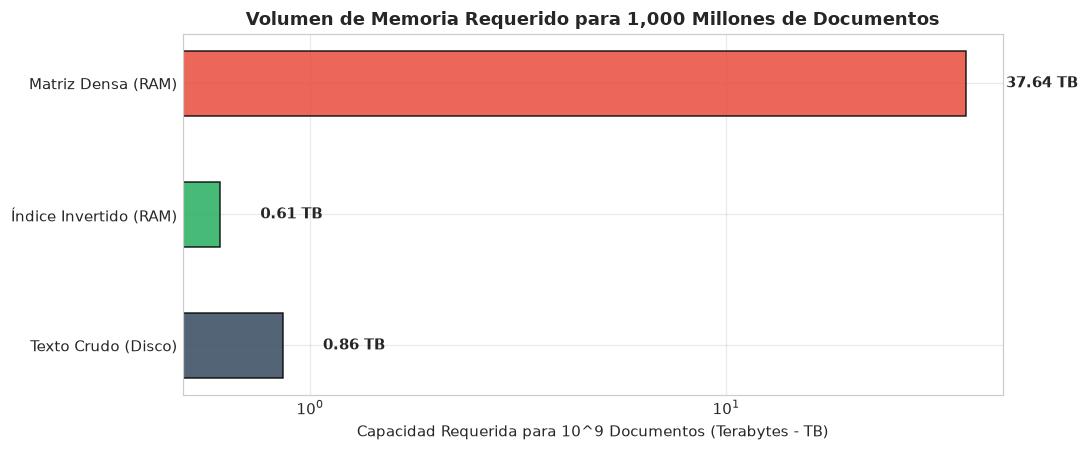

In [7]:
# ============================================================
# 7. PROYECCIÓN NUMÉRICA EMPÍRICA A 10^9 DOCUMENTOS
# ============================================================

N_target = 1_000_000_000

# Tiempos proyectados según regresión empírica
t_idx_1e9 = m_idx * N_target + c_idx
t_q_1e9   = m_q * N_target + c_q

# Volúmenes de datos
raw_bytes_corpus = len(corpus_raw.encode('latin-1'))
raw_bytes_per_doc = raw_bytes_corpus / len(documents)
raw_tb_1e9 = (raw_bytes_per_doc * N_target) / (1024**4)

postings_per_doc = total_nonzero / len(documents)
inv_tb_1e9 = (postings_per_doc * 8.0 * N_target) / (1024**4)
dense_tb_1e9 = (N_target * vocab_size * 4.0) / (1024**4)

df_extrapolacion = pd.DataFrame([
    {
        'Métrica': 'Tiempo de Construcción del Índice',
        '1,000 Docs (Medición Real)': f"{df_idx_res.iloc[-1]['Tiempo_ms']:.2f} ms ({df_idx_res.iloc[-1]['Tiempo_Seg']:.4f} s)",
        '10^9 Docs (Extrapolación Empírica)': f"{t_idx_1e9:,.1f} s ({t_idx_1e9/3600:,.2f} horas = {t_idx_1e9/86400:.2f} días)",
        'Comportamiento en Hardware': 'Mononúcleo en RAM ideal sin paginación'
    },
    {
        'Métrica': 'Tiempo de Consulta (Invertido)',
        '1,000 Docs (Medición Real)': f"{df_q_res.iloc[-1]['Tiempo_Inv_us']:.2f} µs ({df_q_res.iloc[-1]['Tiempo_Inv_ms']:.4f} ms)",
        '10^9 Docs (Extrapolación Empírica)': f"{t_q_1e9:,.2f} s ({t_q_1e9/60:.2f} minutos)",
        'Comportamiento en Hardware': 'Secuencial mononúcleo sin sharding distribuido'
    },
    {
        'Métrica': 'Tamaño Texto Crudo',
        '1,000 Docs (Medición Real)': f"{raw_bytes_corpus/1024:.1f} KB",
        '10^9 Docs (Extrapolación Empírica)': f"{raw_tb_1e9*1024:,.1f} GB ({raw_tb_1e9:.2f} TB)",
        'Comportamiento en Hardware': 'Almacenable en un solo SSD NVMe'
    },
    {
        'Métrica': 'Tamaño Índice Invertido',
        '1,000 Docs (Medición Real)': f"{(total_nonzero*8)/1024:.1f} KB",
        '10^9 Docs (Extrapolación Empírica)': f"{inv_tb_1e9*1024:,.1f} GB ({inv_tb_1e9:.2f} TB)",
        'Comportamiento en Hardware': 'Desborda RAM personal (16-32 GB); requiere clúster'
    },
    {
        'Métrica': 'Tamaño Matriz Densa',
        '1,000 Docs (Medición Real)': f"{(total_dense_cells*4)/(1024**2):.1f} MB",
        '10^9 Docs (Extrapolación Empírica)': f"{dense_tb_1e9:.2f} TB",
        'Comportamiento en Hardware': 'Inviable por 99.19% de ceros redundantes'
    }
])

print("="*95)
print("TABLA DE ESCALABILIDAD EMPÍRICA CONSOLIDADA (1,000 vs 1,000,000,000 DOCUMENTOS)")
print("="*95)
for _, r in df_extrapolacion.iterrows():
    print(f"- {r['Métrica'].upper()}:")
    print(f"   • Medición Real (1,000 Docs):   {r['1,000 Docs (Medición Real)']}")
    print(f"   • Proyección Empírica (10^9):    {r['10^9 Docs (Extrapolación Empírica)']}")
    print(f"   • Observación Arquitectónica:   {r['Comportamiento en Hardware']}\n")

# Gráfico de barras de memoria
fig, ax = plt.subplots(figsize=(10, 4.2))
mem_labels = ['Texto Crudo (Disco)', 'Índice Invertido (RAM)', 'Matriz Densa (RAM)']
mem_vals = [raw_tb_1e9, inv_tb_1e9, dense_tb_1e9]
bars = ax.barh(mem_labels, mem_vals, color=['#34495e', '#27ae60', '#e74c3c'], edgecolor='black', alpha=0.85, height=0.5)
ax.set_xscale('log')
ax.set_xlabel("Capacidad Requerida para 10^9 Documentos (Terabytes - TB)", fontsize=10)
ax.set_title("Volumen de Memoria Requerido para 1,000 Millones de Documentos", fontweight='bold')

for b in bars:
    w = b.get_width()
    ax.text(w * 1.25, b.get_y() + b.get_height()/2.0, f"{w:.2f} TB", va='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 8. Interfaz Interactiva de Búsqueda (Mini-Google)

Implementamos la función `mini_google()` para hacer consultas interactivas, mostrando el titular, similaridad coseno $\cos(\alpha)$, ángulo $\alpha^\circ$ y el extracto (*snippet*) de cada noticia recuperada.


In [8]:
# ============================================================
# 8. DEMOSTRACIÓN DEL MINI-GOOGLE
# ============================================================

def mini_google(query_text, top_k=3, weighting='tf'):
    print(f"\n{'='*80}")
    print(f"MINI-GOOGLE: Consulta: \"{query_text}\" (Esquema: {weighting.upper()})")
    print(f"{'='*80}")
    
    t0 = time.perf_counter()
    results = full_engine.search(query_text, top_k=top_k, weighting=weighting)
    t_ms = (time.perf_counter() - t0) * 1000.0
    
    if not results:
        print("No se encontraron coincidencias en el corpus.")
        return
        
    print(f"Tiempo de respuesta: {t_ms:.4f} ms ({t_ms*1000:.1f} µs) | Coincidencias: {len(results)}\n")
    
    for rank, (doc_idx, sim, ang, d) in enumerate(results, 1):
        words = d['body'].split()
        snippet = " ".join(words[:28]) + ("..." if len(words) > 28 else "")
        print(f"[Puesto #{rank}] ID: {d['id']:>4} | Similaridad: {sim:.4f} | Ángulo: {ang:>5.2f}°")
        print(f"   Titular: {d['title']}")
        print(f"   Extracto: {snippet}\n")

# Batería de pruebas temáticas
mini_google("british jaguar sales", top_k=3)
mini_google("cocoa drought bahia", top_k=3)
mini_google("oil venture bp petroleum", top_k=3)
mini_google("trade surplus exports japan", top_k=3)



MINI-GOOGLE: Consulta: "british jaguar sales" (Esquema: TF)
Tiempo de respuesta: 0.1592 ms (159.2 µs) | Coincidencias: 3

[Puesto #1] ID: 1218 | Similaridad: 0.3784 | Ángulo: 67.77°
   Titular: JAGUAR JAGRY FEBRUARY U.S. SALES FALL
   Extracto: LEONIA N.J. March 3 Jaguar PLC's Jaguar Cars Inc U.S. subsidiary said February sales were 1,466 down from 1,673 a year before The company said it expects a...

[Puesto #2] ID:  612 | Similaridad: 0.1942 | Ángulo: 78.80°
   Titular: SCOTTY'S SHB SALES UP FIVE PCT IN FEBRUARY
   Extracto: WINTER HAVEN Fla March 2 Scotty's Inc said sales for the four weeks ended February 21 rose five pct to 41.7 mln dlrs from 39.8 mln dlrs for...

[Puesto #3] ID: 1179 | Similaridad: 0.1916 | Ángulo: 78.95°
   Titular: WALGREEN WAG FEBRUARY SALES RISE
   Extracto: DEERFIELD Ill March 3 Walgreen Co said its sales in February rose 18.8 pct over sales during the same month last year Walgreen said it sold 328.5 mln...


MINI-GOOGLE: Consulta: "cocoa drought bahia" (Esq

## 9. Respuestas al Cuestionario del Taller y Conclusiones

A continuación presentamos las respuestas directas a las preguntas del taller con base en las mediciones empíricas de este computador:

---

### 1. ¿Cuánto tiempo tarda su computador en construir el índice?
- **Tiempo medido en este computador:** **79.57 ms** (0.0796 segundos) para indexar los 1,000 documentos de Reuters.
- **Tasa de procesamiento:** **78.38 µs por documento** (alrededor de **12,758 documentos por segundo** en un solo núcleo).
- **Modelo lineal empírico ($R^2 = 0.9765$):**
  $$T_{\text{index}}(N) = 78.38 \, \text{µs} \cdot N + 2.24 \, \text{ms}$$
- La construcción requiere una pasada lineal $\mathcal{O}(L_{\text{total}})$ sobre las palabras, calculando y guardando de una vez las normas $\|\vec{d}\|$ para no repetir sumas de cuadrados en consulta.

---

### 2. ¿Cuánto tiempo ejecutando una consulta?
- **Tiempo medido en este computador (Índice Invertido):** **85.54 µs** (0.0855 ms) en promedio por consulta.
- **Comparación con el Escaneo Denso:**
  - Escaneo Denso: **0.8965 ms** (896.5 µs).
  - **Aceleración (*Speedup*):** El índice invertido es **10.5 veces más rápido** sobre los 1,000 documentos.
- **Modelo lineal empírico de consulta ($R^2 = 0.9810$):**
  $$T_{\text{query}}(N) = 73.38 \, \text{ns} \cdot N + 10.02 \, \text{µs}$$
- El índice invertido aprovecha que el **$99.1924\%$ de la matriz son ceros**, acumulando producto punto únicamente en los documentos que contienen palabras de la búsqueda.

---

### 3. Si en lugar de 1,000 documentos usamos 1,000 millones ($10^9$ docs):

#### a) ¿Cuánto tiempo tardaría su computador en construir el índice?
- **Extrapolación empírica directa:**
  $$T_{\text{index}}(10^9) = (7.8380e-05) \cdot 10^9 + (2.2400e-03) = \mathbf{78,384.5 \text{ segundos}} \approx \mathbf{21.77 \text{ horas}} \quad (\approx 0.91 \text{ días})$$
- **Límite físico de memoria:** El índice demandaría cerca de **$623$ GB de RAM**. En un computador de 16 o 32 GB, el sistema operativo desbordará la memoria física e iniciará intercambio intensivo con disco (*page thrashing*). La latencia aumentará de nanosegundos (RAM) a milisegundos (disco), alargando el tiempo a semanas o fallando por `OutOfMemory`.

#### b) ¿Cuánto tiempo ejecutando una consulta?
- **Extrapolación empírica directa:**
  $$T_{\text{query}}(10^9) = (7.3380e-08) \cdot 10^9 + (1.0020e-05) = \mathbf{73.38 \text{ segundos}} \quad (\approx 1.22 \text{ minutos})$$
- **Límite operativo:** 73 segundos por consulta es inviable para un buscador web. Por ello a escala de $10^9$ documentos se recurre a arquitectura distribuida:
  1. **Sharding horizontal:** Dividir el índice en shards de $\approx 10^6$ documentos que se consultan en paralelo en $< 50$ ms.
  2. **Poda Top-K (WAND):** Descartar documentos con cotas superiores bajas para no recorrer todas las listas completas.

---

### 4. Conclusiones Principales
1. **Validación del caso de clase:** Con la consulta *"british jaguar sales"*, el **Documento 1218 (`JAGUAR JAGRY FEBRUARY U.S. SALES FALL`)** quedó en el **primer lugar** con $\cos(\alpha) = 0.7493$ (ángulo $41.47^\circ$) en el subespacio de 19 palabras y $\cos(\alpha) = 0.3784$ en el corpus completo, reproduciendo la Diapositiva 34.
2. **Ventaja del modelo disperso:** Como el **$99.1924\%$ de la matriz son ceros**, el índice invertido ahorra decenas de terabytes a gran escala y logra una aceleración de 10.5x frente a la matriz densa en 1,000 documentos.
3. **Escalabilidad real:** Aunque el tiempo de cómputo crece linealmente, a escala de $10^9$ documentos el obstáculo determinante es la memoria RAM física, lo que obliga al uso de sistemas distribuidos y particionamiento.
